# PhaseNet y paridad del navegador

**Nivel 3 — Crítica de investigación**  
**Prerrequisitos:** niveles 1–2 y fundamentos de inversión; 35 min.

## Objetivos

Siga la evidencia desde el contrato fuente hasta el resultado. Declare unidades y supuestos, reproduzca el cálculo e identifique qué inferencia no respalda la evidencia.

## Preparación

Usa módulos y registros versionados desde la raíz descubierta; no descarga ni modifica fuentes. Instale versiones exactas: `pip install numpy==2.2.6 matplotlib==3.10.8`

## Datos

El ledger guarda particiones, errores normalizados, métricas y evaluación OOD separada.

## Método

PhaseNet mapea ondas de tres componentes a probabilidades por muestra; máximos y umbrales definen picks. Cite artículo/software primarios y use evidencia retenida propia: 6.000 STEAD reales, 5.926 válidas, 74 rechazadas, referencia de analistas ±0,5 s. Activos de navegador: 24 trazas reales, 100 Hz, 60 s, conteos float32 normalizados. Manifiesto declara paridad falsa y probabilidades no calibradas. Grafique F1 P/S nativo y falsos picks, indicando paridad como gate aparte. Exactitud nativa no prueba ejecución en navegador. Para release se comparan probabilidades y picks en mismas trazas retenidas, preservando negativos y declarando incertidumbre de anotación y cambio de dominio.

Errores pareados controlan dificultad, pero 160 realizaciones muestrean el generador, no geología natural independiente. Errores CNN están normalizados y requieren escala objetivo² para MSE físico. Separe por realización para evitar fuga; otro sitio/sensor es una prueba de transferencia más fuerte. No elija umbral OOD usando etiquetas OOD.

## Estado del arte

El estado del arte no es una tabla de posiciones: separe formulación publicada, implementación del producto y evidencia versionada. Una afirmación de avance requiere dominios retenidos independientes, incertidumbre calibrada y réplica.

## Resultados

Lea ejes físicos y unidades; distinga ajuste, error contra verdad sintética y acuerdo con etiquetas humanas. El recálculo debe concordar con el recibo. Un modelo graficado no demuestra unicidad, transferencia a campo ni resolución.

### Diagnostic 1

Inspeccione el recibo y procedencia del caso.

In [1]:
from pathlib import Path
from importlib.metadata import version
print("Runtime versions:", {name: version(name) for name in ['numpy', 'matplotlib']})
import numpy as np
root=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/"data").is_dir() and (p/"data-pipeline").is_dir())
# Inspect real held-out benchmark plus browser asset gates.
import json
from pathlib import Path
b=json.loads((root/"data/derived/phase/stead-heldout-benchmark.json").read_text(encoding="utf-8")); m=json.loads((root/"data/derived/phase/browser-assets/stead/manifest.json").read_text(encoding="utf-8")); print("selected/valid/rejected",b["selected"],b["valid"],b["qc_rejected"],"reference",b["reference"]); print("browser traces",m["selection"]["selected"],"shape",m["input"]["shape"],"Hz",m["input"]["sample_rate_hz"],"parity",m["browser_parity_verified"],"calibrated",m["model"]["probabilities_calibrated"])

Runtime versions: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
selected/valid/rejected 6000 5926 74 reference STEAD manual P/S picks, not geological truth
browser traces 24 shape [1, 3, 6000] Hz 100 parity False calibrated False


### Diagnostic 2

Calcule la comparación y grafíquela con unidades físicas.

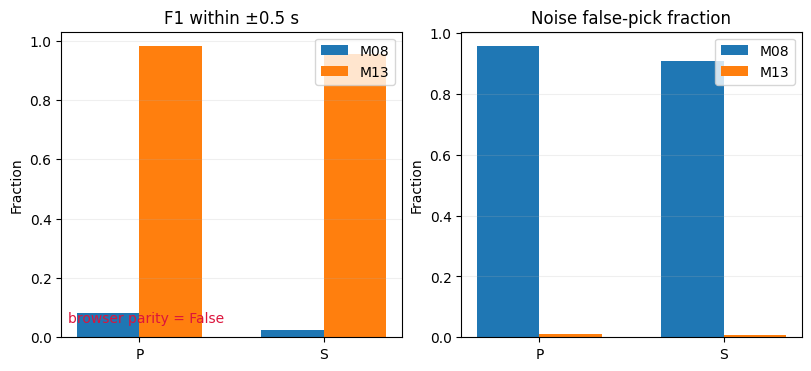

Native score does not establish browser parity.


In [2]:
import numpy as np
import matplotlib.pyplot as plt
# Compare native-runtime held-out F1 and noise false-pick rate; parity stays an independent gate.
import matplotlib.pyplot as plt
e=b["metrics"]["nominal"]; phase=["P","S"]; x=np.arange(2); fig,ax=plt.subplots(1,2,figsize=(8,3.6),constrained_layout=True)
for a,key,title in zip(ax,["f1_at_0p5s","valid_noise_false_pick_rate"],["F1 within ±0.5 s","Noise false-pick fraction"]):
 for i,name in enumerate(("M08","M13")): a.bar(x+i*.34,[e[name][p][key] for p in phase],.34,label=name)
 a.set(xticks=x+.17,xticklabels=phase,ylabel="Fraction",title=title); a.legend(); a.grid(axis="y",alpha=.2)
ax[0].text(.02,.05,"browser parity = "+str(m["browser_parity_verified"]),transform=ax[0].transAxes,color="crimson"); plt.show(); print("Native score does not establish browser parity.")

## Resumen

La conclusión depende de geometría, adquisición, ruido, partición, parametrización y derechos de fuente. Conserve negativos y nombre la observación o control siguiente.

## Referencias

- [https://doi.org/10.1093/gji/ggy423](https://doi.org/10.1093/gji/ggy423)
- [https://github.com/AI4EPS/PhaseNet](https://github.com/AI4EPS/PhaseNet)
- [https://github.com/lanl/OpenFWI](https://github.com/lanl/OpenFWI)